 # Data Visulaization assign.2

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object','category']).columns.tolist()
print("\nNumeric:", numeric_cols)
print("Categorical:", categorical_cols)

In [ ]:
df = sns.load_dataset("taxis")
print("Shape:", df.shape)
df.head()

Shape: (6433, 14)


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [ ]:
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nPercentage missing:")
print(df.isnull().mean()*100)



Missing values per column:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Percentage missing:
pickup             0.000000
dropoff            0.000000
passengers         0.000000
distance           0.000000
fare               0.000000
tip                0.000000
tolls              0.000000
total              0.000000
color              0.000000
payment            0.683973
pickup_zone        0.404166
dropoff_zone       0.699518
pickup_borough     0.404166
dropoff_borough    0.699518
dtype: float64


In [ ]:
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object','category']).columns.tolist()
print("\nNumeric:", numeric_cols)
print("Categorical:", categorical_cols)



Numeric: ['passengers', 'distance', 'fare', 'tip', 'tolls', 'total']
Categorical: ['color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough']


In [ ]:
for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        df[col].fillna(df[col].median(), inplace=True)


In [ ]:
for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col].fillna(df[col].mode()[0], inplace=True)


/tmp/ipykernel_937/670159539.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0], inplace=True)


In [ ]:

# e.g., if pickup/dropoff is still missing
df.dropna(subset=['pickup', 'dropoff'], inplace=True)


In [ ]:
print("\nAfter cleaning - Missing:", df.isnull().sum().sum())
print("Cleaned shape:", df.shape)



After cleaning - Missing: 0
Cleaned shape: (6433, 14)


In [ ]:

df['pickup'] = pd.to_datetime(df['pickup'])
df_sorted = df.sort_values('pickup')


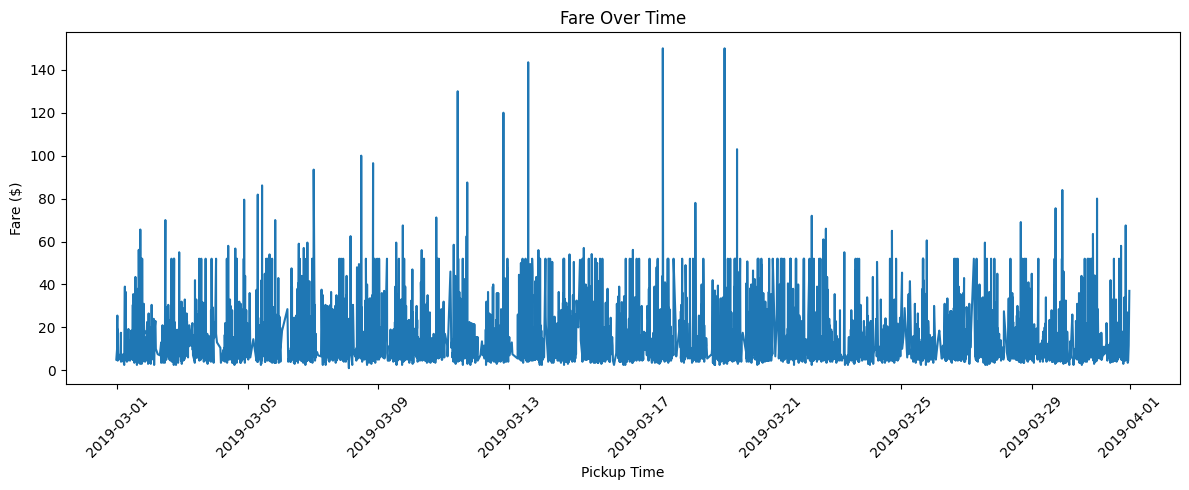

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(df_sorted['pickup'], df_sorted['fare'])
plt.title('Fare Over Time')
plt.xlabel('Pickup Time')
plt.ylabel('Fare ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

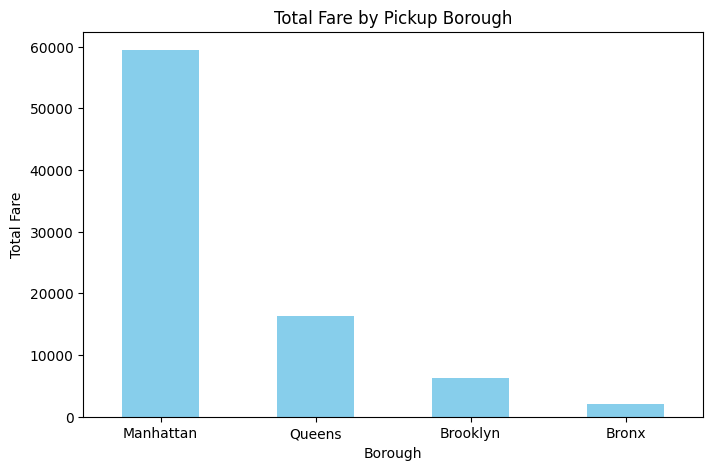

In [ ]:
fare_by_borough = df.groupby('pickup_borough')['fare'].sum().sort_values(ascending=False)
plt.figure(figsize=(8,5))
fare_by_borough.plot(kind='bar', color='skyblue')
plt.title('Total Fare by Pickup Borough')
plt.xlabel('Borough')
plt.ylabel('Total Fare')
plt.xticks(rotation=0)
plt.show()


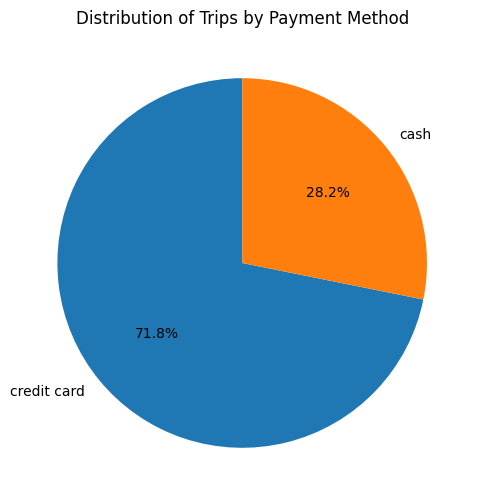

In [ ]:
payment_counts = df['payment'].value_counts()
plt.figure(figsize=(6,6))
plt.pie(payment_counts, labels=payment_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Trips by Payment Method')
plt.show()

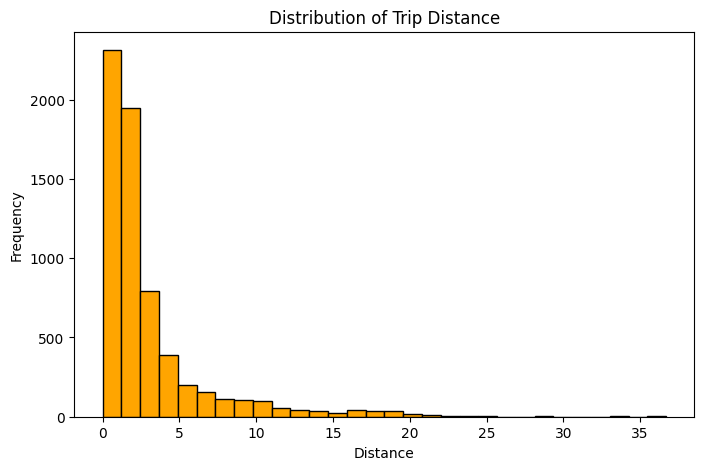

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df['distance'], bins=30, color='orange', edgecolor='black')
plt.title('Distribution of Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.show()


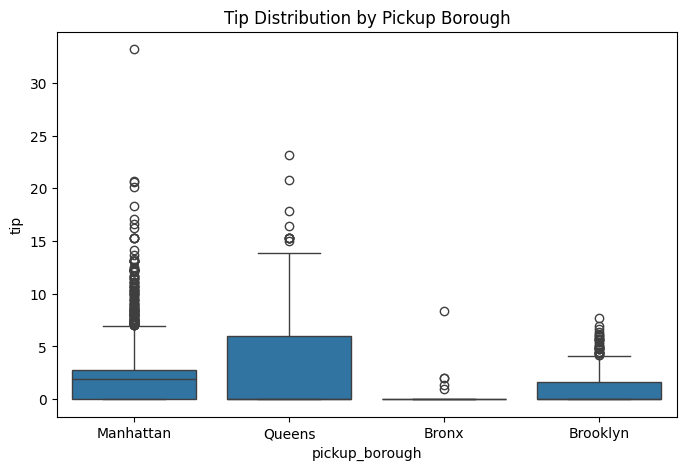

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(x='pickup_borough', y='tip', data=df)
plt.title('Tip Distribution by Pickup Borough')
plt.show()

/tmp/ipykernel_937/2776774690.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='pickup_borough', data=df, palette='viridis')


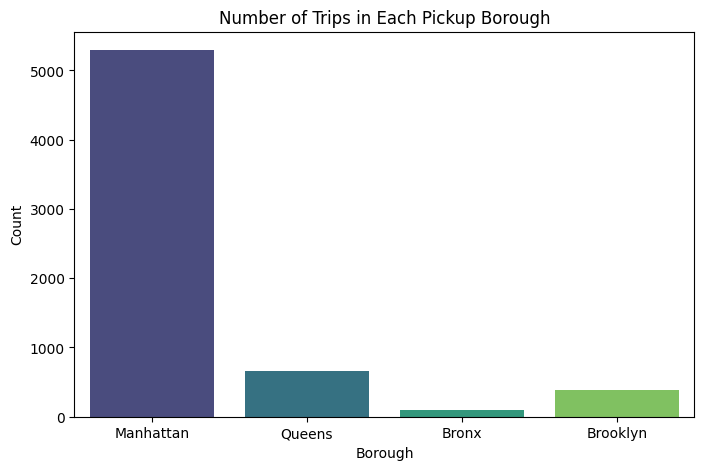

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(x='pickup_borough', data=df, palette='viridis')
plt.title('Number of Trips in Each Pickup Borough')
plt.xlabel('Borough')
plt.ylabel('Count')
plt.show()


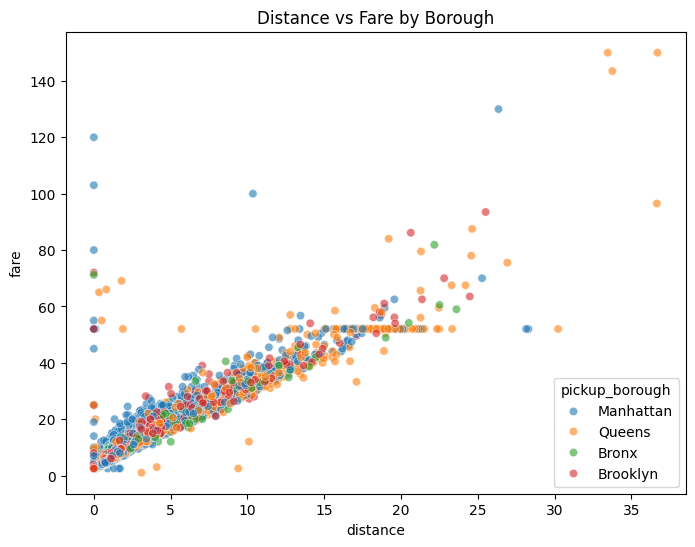

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(x='distance', y='fare', hue='pickup_borough', data=df, alpha=0.6)
plt.title('Distance vs Fare by Borough')
plt.show()


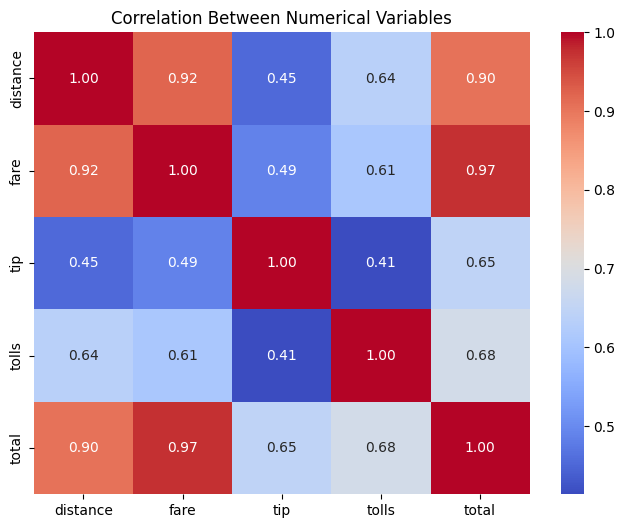

In [ ]:
plt.figure(figsize=(8,6))
corr = df[['distance','fare','tip','tolls','total']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Between Numerical Variables')
plt.show()


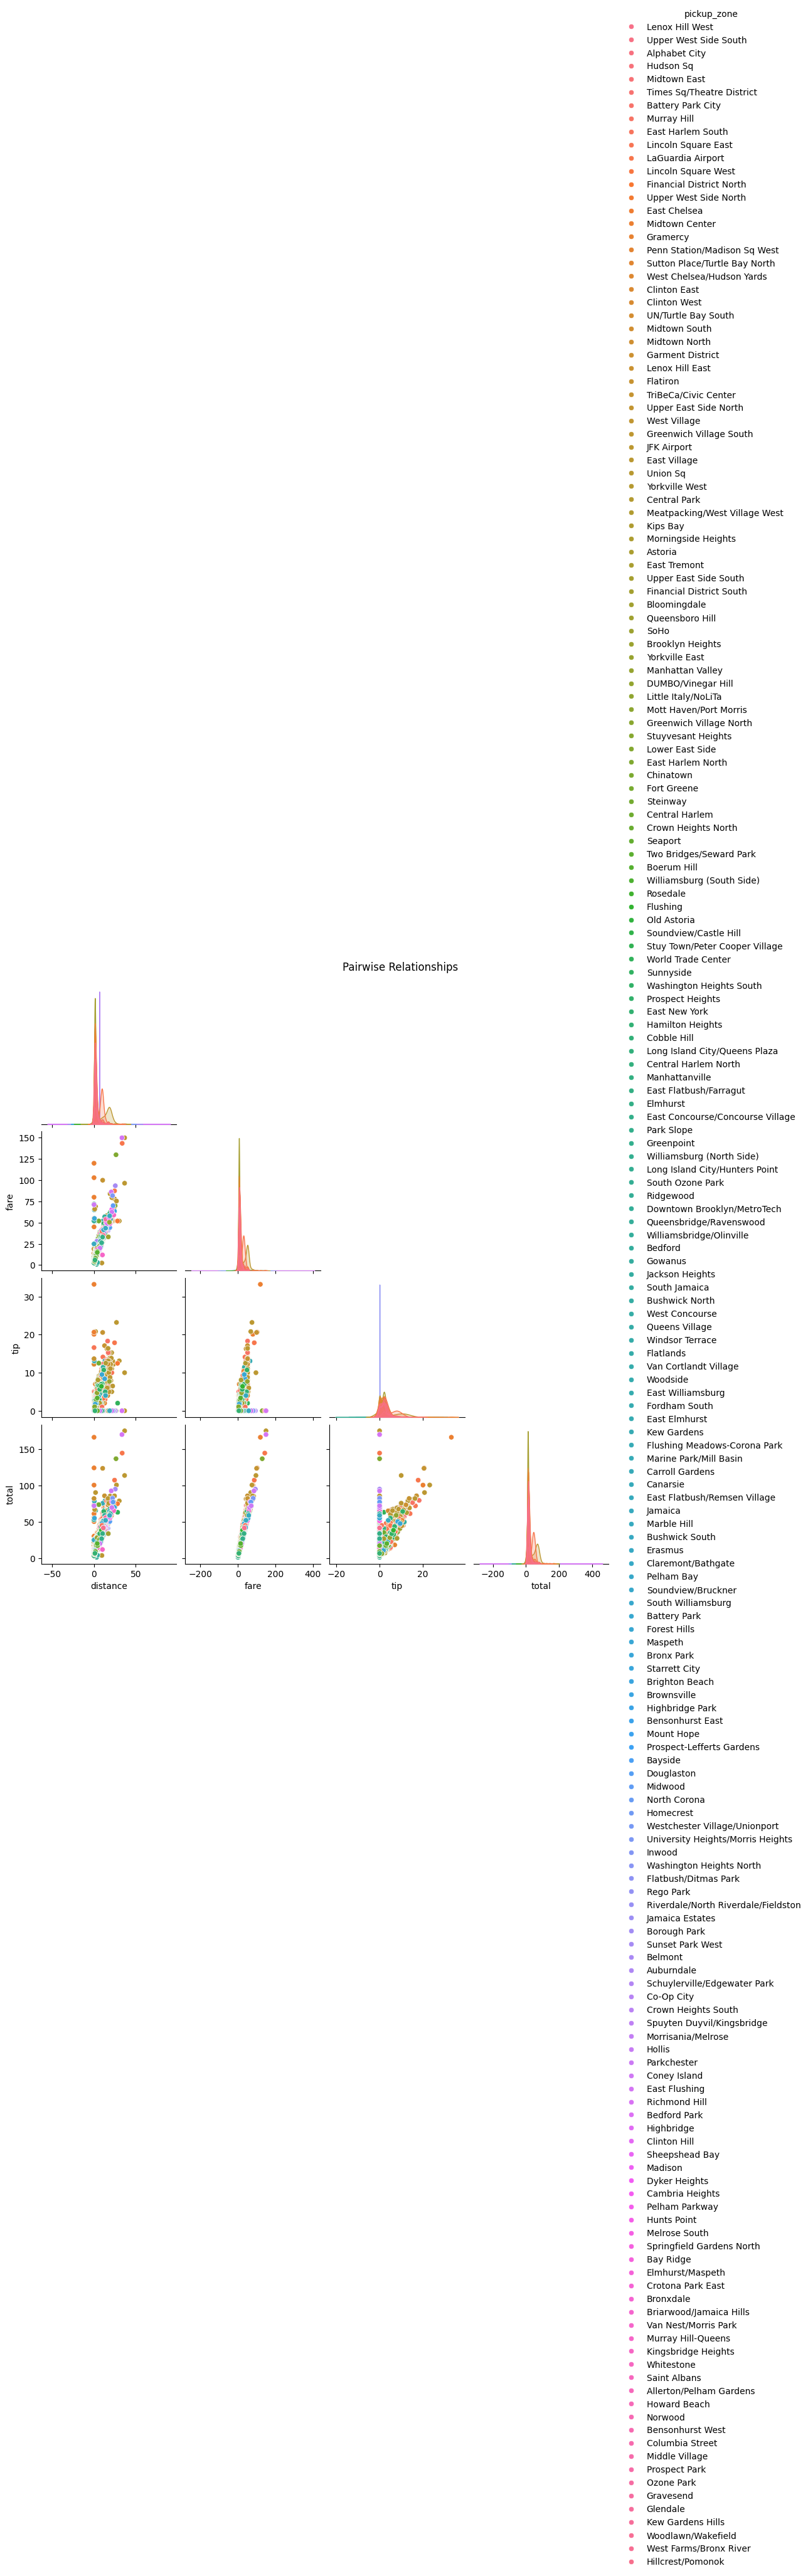

In [ ]:
sns.pairplot(df[['distance','fare','tip','total','pickup_zone']],
             hue='pickup_zone', diag_kind='kde', corner=True)
plt.suptitle('Pairwise Relationships', y=1.02)
plt.show()

/tmp/ipykernel_937/1532247244.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='payment', y='fare', data=df, palette='Set2')


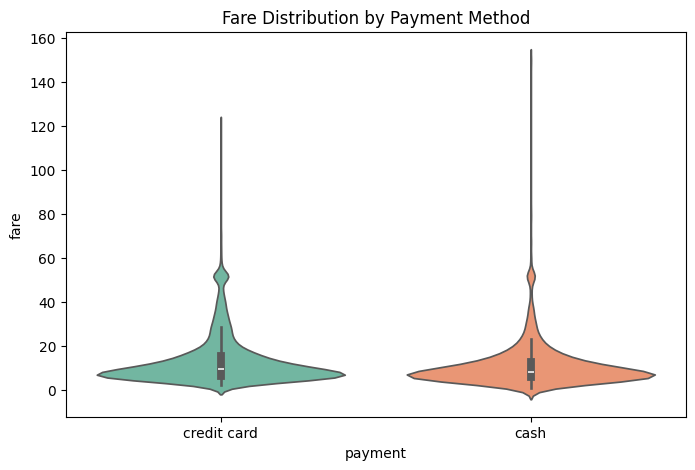

In [ ]:
plt.figure(figsize=(8,5))
sns.violinplot(x='payment', y='fare', data=df, palette='Set2')
plt.title('Fare Distribution by Payment Method')
plt.show()